In [1]:
# Projeto HELENA: Predição de Câncer de Pulmão
#**Autoria:** Luidy Costa dos Santos  
#**Versão:** 5.0.0 - Adequação Metodológica Experimental  

### 1. Caracterização e Proveniência do Dataset

#**Proveniência e Referências**
#Os dados utilizados neste projeto são de natureza sintética, gerados a partir do simulador Synthea, construídos especificamente para estudos de Machine Learning no diagnóstico precoce de câncer de pulmão. A natureza sintética dos dados assegura a anonimização total e elimina restrições de privacidade.
#* **Autores:** J. N. Kather et al.
#* **Ano:** 2022
#* **Fontes:** Scientific Reports e Harvard Dataverse[cite: 14].
#* **Licença:** CC0 1.0 Universal (Public Domain Dedication) - Padrão Dataverse.
#* **Citações Oficiais:**
  #1. J. N. Kather et al., “Synthetic patient data for early lung cancer diagnosis,” *Scientific Reports*, vol. 12, p. 23011, 2022. DOI: 10.1038/s41598-022-23011-4[cite: 14].
  #2. Harvard Dataverse, “Replication Data for: Synthetic patient data for early lung cancer diagnosis,” Harvard Dataverse, V1. DOI: 10.7910/DVN/Q5LK5A. Disponível em: https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/Q5LK5A[cite: 14]

#**Caracterização Clínica e Natureza dos Dados**
#* **Dimensões Originais:** Aproximadamente 26.295 registros e 788 atributos[cite: 14].
#* **Natureza:** Dados clínicos simulando registros eletrônicos de saúde (EHR), englobando variáveis de estilo de vida e manifestações sintomáticas[cite: 14].
#* **Variável-Alvo (`label` / `Target`):** Classificação de risco do paciente, sendo **0 = Saudável** e **1 = Doente**. A base simula um cenário real de triagem e é altamente desbalanceada.

#**Objetivo Experimental**
#O objetivo é maximizar o **Recall (Sensibilidade)** da classe 1. Clinicamente, busca-se mitigar Falsos Negativos. Como critérios secundários de avaliação, utilizaremos a Especificidade, ROC-AUC e F1-score[cite: 14].

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
import joblib # Adicionado para exportação do modelo

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.inspection import permutation_importance 
from sklearn.preprocessing import StandardScaler
from scipy.stats import friedmanchisquare

from sklearn.metrics import (
    confusion_matrix, make_scorer, ConfusionMatrixDisplay, recall_score,           
    accuracy_score, classification_report, roc_curve, roc_auc_score,            
    precision_recall_curve, average_precision_score   
)
import shap

warnings.filterwarnings('ignore')
sns.set(style="whitegrid")
shap.initjs()

def linha(tamanho=85):
    print("_" * tamanho)

def dimensoes(dataframe, opcao):
    if opcao == 0:
        print(f"Dimensões atuais do dataframe: {dataframe.shape}")
        linha()
    elif opcao == 1:
        print(f"Dimensões atuais do dataframe: {dataframe.shape}")
        linha()
        display(dataframe.head())

In [3]:
### Passo 2: Análise Exploratória de Dados (EDA)
#A Análise Exploratória (EDA) é fundamental para entendermos a distribuição da nossa variável alvo e como as características clínicas se correlacionam antes da modelagem.

In [4]:
def gerar_eda(dataframe, classe='Target'):
    print("\n--- ANÁLISE EXPLORATÓRIA DE DADOS (EDA) ---")
    
    # 1. Distribuição da Classe Alvo
    plt.figure(figsize=(6, 4))
    ax = sns.countplot(data=dataframe, x=classe, palette='Set2')
    plt.title("Distribuição da Variável Alvo (Target: 0=Saudável, 1=Doente)")
    for p in ax.patches:
        ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')
    plt.show()

    # 2. Matriz de Correlação
    plt.figure(figsize=(14, 10))
    corr = dataframe.corr()
    sns.heatmap(corr, annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title("Matriz de Correlação das Variáveis Clínicas")
    plt.show()

In [5]:
### Passos 3 a 11: Carregamento, Filtragem e Tratamento de Dados
#Nesta etapa, o dataset bruto é carregado e as colunas são renomeadas para termos médicos mais claros. Valores nulos e variáveis categóricas (como 'Fumo' e 'Idade') são tratadas. Duplicatas são removidas e aplicamos o método de *One-Hot Encoding* (get_dummies) para preparar os dados matematicamente para os algoritmos.

In [6]:
def carregar_dataset(caminho):
    linha(90)
    print("INICIANDO CARREGAMENTO DE DATASET")
    print(f"Buscando arquivo {caminho}...")

    try:
        print("Arquivo encontrado! Carregando dataset...")
        df_sujo = pd.read_csv(caminho, low_memory=False)
        print("Arquivo bruto carregado")
        dimensoes(df_sujo, 1)
        return df_sujo
    except FileNotFoundError:
        print(f"Arquivo {caminho} não encontrado. Certifique-se de que o nome está correto.")
        return None
    except Exception as error:
        print(f"Erro desconhecido: {error}")
        return None

def investigar_duplicatas(df_sujo):
    print("\n--- ANÁLISE E TRATAMENTO DE REGISTROS DUPLICADOS ---")
    
    total_original = df_sujo.shape[0]
    duplicadas_originais = df_sujo.duplicated().sum()
    
    # Fazendo a seleção inicial de colunas clínicas, mas MANTENDO o ID do paciente ('ptnum')
    mapa_colunas={
        'ptnum': 'ID_Paciente', 'label': 'Target', 'C-424144002': 'Idade', 
        'C-263495000': 'Genero', 'C-72166-2': 'Fumo', 'C-9279-1': 'Freq_Respiratoria', 
        'C-8867-4': 'Freq_Cardiaca', 'C-8480-6': 'Pressao_Sistolica', 
        'C-8462-4': 'Pressao_Diastolica', 'C-267036007': 'Falta_Ar', 
        'C-66857006': 'Tosse_Sangue', 'C-39156-5': 'IMC', 'C-2708-6': 'Sat_Oxigenio', 
        'C-49727002': 'Tosse', 'C-84229001': 'Fadiga', 'C-7200002': 'Alcoolismo', 
        'C-56018004': 'Chiado'
    }
    colunas_existentes = [c for c in mapa_colunas.keys() if c in df_sujo.columns]
    df_analise = df_sujo[colunas_existentes].rename(columns=mapa_colunas)
    
    # Isolando apenas as features clínicas (sem o ID do paciente e sem o Target)
    features_clinicas = df_analise.drop(columns=['ID_Paciente', 'Target']).columns.tolist()
    
    # 1. Quantos pacientes únicos existem?
    pacientes_unicos = df_analise['ID_Paciente'].nunique()
    
    # 2. Investigando se as "duplicatas" são a mesma pessoa ou pessoas diferentes com mesmos sintomas
    duplicatas_clinicas = df_analise.duplicated(subset=features_clinicas).sum()
    
    print(f"Total de registros na base original: {total_original}")
    print(f"Linhas idênticas na base original inteira (todas as 788 colunas): {duplicadas_originais}")
    print(f"Total de pacientes únicos (ID_Paciente): {pacientes_unicos}")
    print(f"Registros com quadro clínico EXATAMENTE IGUAL: {duplicatas_clinicas}")
    print("\nJustificativa Metodológica:")
    print("Muitos pacientes distintos compartilham exatamente os mesmos sintomas básicos e faixa de sinais vitais.")
    print("Remover duplicatas apenas nas variáveis de sintomas destrói o desbalanceamento real da base populacional e elimina pacientes únicos válidos.")
    
    # Ação Correta: NÃO faremos drop_duplicates() cego! Faremos drop_duplicates apenas se o ID_Paciente for duplicado.
    df_final = df_analise.drop_duplicates(subset=['ID_Paciente'])
    print(f"\nDimensão após remover pacientes repetidos (mantendo indivíduos reais com sintomas iguais): {df_final.shape}")
    linha(90)
    
    # Remover o ID do paciente agora para ir para a modelagem
    return df_final.drop(columns=['ID_Paciente'])

def filtrar_colunas(dataframe):
    mapa_colunas={
        'label': 'Target',           
        'C-424144002': 'Idade', 
        'C-263495000': 'Genero', 
        'C-72166-2': 'Fumo',
        'C-9279-1': 'Freq_Respiratoria', 
        'C-8867-4': 'Freq_Cardiaca', 
        'C-8480-6': 'Pressao_Sistolica', 
        'C-8462-4': 'Pressao_Diastolica',
        'C-267036007': 'Falta_Ar', 
        'C-66857006': 'Tosse_Sangue', 
        'C-39156-5': 'IMC', 
        'C-2708-6': 'Sat_Oxigenio', 
        'C-49727002': 'Tosse', 
        'C-84229001': 'Fadiga', 
        'C-7200002': 'Alcoolismo', 
        'C-56018004': 'Chiado'
    }
    print("Filtrando Colunas...")
    linha()
    colunas_existentes = [c for c in mapa_colunas.keys() if c in dataframe.columns]
    df = dataframe[colunas_existentes].rename(columns=mapa_colunas)
    dimensoes(df, 0)
    return df
    
def tratar_dados(dataframe):
    print("Tratando valores booleanos...")
    linha()
    booleanos = ['Falta_Ar', 'Tosse_Sangue', 'Tosse', 'Fadiga', 'Alcoolismo', 'Chiado']
    for c in booleanos:
        if c in dataframe.columns:
            dataframe[c] = dataframe[c].fillna(0).astype(str).replace({
                'True':1, "1":1, "1.0":1, 'False':0, '0':0, "0.0":0
            })
            dataframe[c] = pd.to_numeric(dataframe[c], errors='coerce').fillna(0).astype(int)
            
    print("Tratando valores categóricos...")
    linha()
    categoricos = ['Freq_Respiratoria', 'Freq_Cardiaca', 'Pressao_Sistolica', 'Pressao_Diastolica']
    for c in categoricos:
        if c in dataframe.columns:
            dataframe[c] = dataframe[c].fillna('normal')

    if "Fumo" in dataframe.columns:
        dataframe["Fumo"] = dataframe["Fumo"].fillna("fumante_ativo").replace({
            "never":"não_fumante", "former":"ex_fumante"
        })
    if "Idade" in dataframe.columns:
        dataframe['Idade'] = dataframe['Idade'].replace({
            "50t70":"50_a_70_anos", "gt70":"Mais_de_70", "30t50":"30_a_50_anos"
        })
    
    print("Verificando e apagando duplicatas...")
    duplicatas = dataframe.duplicated().sum()
    print(f'{duplicatas} duplicatas encontradas e removidas.')
    linha()
    dataframe = dataframe.drop_duplicates()
    
    print("Criando dummies...")
    linha()
    dataframe = pd.get_dummies(dataframe, drop_first=True)
    dataframe = dataframe.replace({True: 1, False: 0})

    print("Dados tratados com sucesso!")
    dimensoes(dataframe, 1)
    return dataframe

In [7]:
### Passo 12: Prevenção de Data Leakage e Divisão Treino/Teste
#Os dados são separados em 70% para treino e 30% para teste. Aplicamos o `StandardScaler` **apenas** após a divisão, ajustando-o (fit) exclusivamente nos dados de treino. Isso previne o vazamento de dados (Data Leakage), garantindo que o modelo não tenha acesso a informações do conjunto de teste durante o aprendizado.

In [8]:
def preparar_dados_treino(dataframe, classe):
    print("\nPreparando o ambiente para treino dos modelos (Sem Data Leakage)")
    x = dataframe.drop(columns=classe)
    y = dataframe[classe]
    
    x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.3, stratify=y, random_state=42)

    print(f"   -> Treino: {x_treino.shape}")
    print(f"   -> Teste:  {x_teste.shape}")
    linha()
    
    # Criando PIPELINES para cada algoritmo (O Scaler agora está DENTRO da validação)
    pipelines = {
        "Baseline (Dummy)": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', DummyClassifier(random_state=42))
        ]),
        "Regressão Logística": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', LogisticRegression(class_weight='balanced', random_state=42))
        ]),
        "Árvore de Decisão": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=42))
        ]),
        "Random Forest": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
        ]),
        "SVM (Support Vector)": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', SVC(probability=True, class_weight='balanced', random_state=42))
        ]),
        "Gradient Boosting": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', GradientBoostingClassifier(random_state=42))
        ])
    }

    return x_treino, x_teste, y_treino, y_teste, pipelines

In [9]:
### Passos 13 a 20: Definição, Otimização (GridSearch) e Teste Estatístico
#Testamos múltiplas famílias de algoritmos contra um Baseline (Dummy). Usamos o `GridSearchCV` para encontrar os melhores hiperparâmetros com foco primário no **Recall**. Caso haja empate técnico (margem de 2%), utilizamos a **Especificidade** como critério de desempate. O Teste Não-Paramétrico de Friedman atesta se a diferença de desempenho entre os modelos é estatisticamente significativa.

In [10]:
def preparar_dados_treino(dataframe, classe):
    print("\nPreparando o ambiente para treino dos modelos (Sem Data Leakage)")
    x = dataframe.drop(columns=classe)
    y = dataframe[classe]
    
    x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.3, stratify=y, random_state=42)

    print(f"   -> Treino: {x_treino.shape}")
    print(f"   -> Teste:  {x_teste.shape}")
    linha()
    
    # Criando PIPELINES para cada algoritmo (O Scaler agora está DENTRO da validação)
    pipelines = {
        "Baseline (Dummy)": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', DummyClassifier(random_state=42))
        ]),
        "Regressão Logística": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', LogisticRegression(class_weight='balanced', random_state=42))
        ]),
        "Árvore de Decisão": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=42))
        ]),
        "Random Forest": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
        ]),
        "SVM (Support Vector)": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', SVC(probability=True, class_weight='balanced', random_state=42))
        ]),
        "Gradient Boosting": Pipeline([
            ('scaler', StandardScaler()), 
            ('clf', GradientBoostingClassifier(random_state=42))
        ])
    }

    return x_treino, x_teste, y_treino, y_teste, pipelines

def otimizar_e_comparar_algoritmos(x_treino, y_treino, pipelines):
    print("Iniciando Busca de Hiperparâmetros (GridSearchCV com Pipeline)...")
    print("Critério Primário: Recall | Critérios Secundários: Especificidade, ROC-AUC e F1-score")
    linha()
    
    # Os nomes dos parâmetros agora exigem o prefixo 'clf__' por causa do Pipeline
    param_grids = {
        "Baseline (Dummy)": {'clf__strategy': ['stratified', 'most_frequent']},
        "Regressão Logística": {'clf__C': [0.01, 0.1, 1, 10], 'clf__solver': ['liblinear']},
        "Árvore de Decisão": {'clf__max_depth': [None, 5, 10], 'clf__min_samples_split': [2, 5]},
        "Random Forest": {'clf__n_estimators': [50, 100], 'clf__max_depth': [None, 10]},
        "SVM (Support Vector)": {'clf__C': [0.1, 1, 10], 'clf__kernel': ['linear', 'rbf']},
        "Gradient Boosting": {'clf__n_estimators': [50, 100], 'clf__learning_rate': [0.01, 0.1]}
    }

    # Avaliando Múltiplas Métricas como exigido
    scoring_dict = {
        'recall': 'recall',
        'especificidade': make_scorer(recall_score, pos_label=0),
        'roc_auc': 'roc_auc',
        'f1': 'f1',
        'precision': 'precision',
        'accuracy': 'accuracy'
    }
    
    kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    resultados = []
    detalhes_folds = []
    resultados_recall_folds = {}
    melhores_modelos = {}

    print(f"{'MODELO':<22} | {'RECALL (± DESVIO)':^18} | {'ESPECIF. (± DESVIO)':^20}")
    linha()
    
    for nome, modelo in pipelines.items():
        grid = GridSearchCV(modelo, param_grids[nome], cv=kfold, scoring=scoring_dict, refit='recall', n_jobs=-1)
        grid.fit(x_treino, y_treino)
        
        melhores_modelos[nome] = grid.best_estimator_
        best_index = grid.best_index_
        
        # Extraindo médias da validação cruzada
        media_recall = grid.cv_results_['mean_test_recall'][best_index]
        desvio_recall = grid.cv_results_['std_test_recall'][best_index]
        media_espec = grid.cv_results_['mean_test_especificidade'][best_index]
        desvio_espec = grid.cv_results_['std_test_especificidade'][best_index]
        media_auc = grid.cv_results_['mean_test_roc_auc'][best_index]
        media_f1 = grid.cv_results_['mean_test_f1'][best_index]
        
        # Coletando métricas exatas por Fold para salvar no CSV (Exigência 8)
        for i in range(5):
            detalhes_folds.append({
                'Modelo': nome,
                'Fold': i + 1,
                'Recall': grid.cv_results_[f'split{i}_test_recall'][best_index],
                'Especificidade': grid.cv_results_[f'split{i}_test_especificidade'][best_index],
                'ROC_AUC': grid.cv_results_[f'split{i}_test_roc_auc'][best_index],
                'F1_Score': grid.cv_results_[f'split{i}_test_f1'][best_index],
                'Precision': grid.cv_results_[f'split{i}_test_precision'][best_index],
                'Accuracy': grid.cv_results_[f'split{i}_test_accuracy'][best_index]
            })
            
        folds_scores = [grid.cv_results_[f'split{i}_test_recall'][best_index] for i in range(5)]
        resultados_recall_folds[nome] = folds_scores
        
        resultados.append({
            'Modelo': nome,
            'Recall': media_recall,
            'Especificidade': media_espec,
            'ROC_AUC': media_auc,
            'F1_Score': media_f1
        })
        
        str_recall = f"{media_recall:.2%} ± {desvio_recall:.2%}"
        str_espec = f"{media_espec:.2%} ± {desvio_espec:.2%}"
        print(f"{nome:<22} | {str_recall:^18} | {str_espec:^20}")

    # Salvar resultados brutos (Exigência 8)
    pd.DataFrame(detalhes_folds).to_csv("resultados_cv.csv", index=False)
    print("\n[Arquivo 'resultados_cv.csv' gerado com sucesso na raiz do projeto]")
    linha()
    
    # Lógica de Escolha Metodológica e Transparente (Exigência 10)
    df_resultados = pd.DataFrame(resultados).sort_values(
        by=['Recall', 'Especificidade', 'ROC_AUC', 'F1_Score'], 
        ascending=[False, False, False, False]
    ).reset_index(drop=True)
    
    nome_vencedor = df_resultados.iloc[0]['Modelo']
    print(f"Vencedor pela Regra Múltipla de Ordenação: {nome_vencedor} (Recall: {df_resultados.iloc[0]['Recall']:.2%})")
    
    # Teste de Friedman
    print("\nRealizando Teste Não Paramétrico de Friedman (Scores de Recall)...")
    scores_lista = list(resultados_recall_folds.values())
    stat, p_valor = friedmanchisquare(*scores_lista)
    print(f"Estatística de Friedman: {stat:.4f} | P-valor: {p_valor:.4f}")
    if p_valor < 0.05:
        print("Interpretação: Há diferença estatística significativa (Rejeita-se a Hipótese Nula).")
    else:
        print("Interpretação: Não há evidência de diferença estatística forte entre os modelos.")
    linha()
    
    modelo_vencedor = melhores_modelos[nome_vencedor]
    # Retreinar vencedor com o Pipeline final ajustado aos dados de treino
    modelo_vencedor.fit(x_treino, y_treino)
    
    return modelo_vencedor, nome_vencedor

In [11]:
### Passos 21 a 23: Avaliação de Desempenho e Erros Críticos
#Verificamos a performance final do modelo vencedor em dados nunca vistos (Teste). Analisamos as métricas globais, as Curvas ROC e Precision-Recall, e isolamos qualitativamente os **Falsos Negativos** (pacientes que o modelo disse estarem saudáveis, mas que possuem câncer), pois este é o risco crítico do projeto.

In [12]:
def gerar_relatorio_metricas(y_teste, predicao):
    print("\nRelatório de Classificação no Conjunto de Teste Final:")
    print(classification_report(y_teste, predicao))
    linha()

def gerar_matriz_confusao(y_teste, predicao, nome_modelo):
    fig, ax = plt.subplots(figsize=(6, 4))
    
    # O parâmetro display_labels substitui o 0 e 1
    ConfusionMatrixDisplay.from_predictions(
        y_teste, 
        predicao, 
        display_labels=['Saudável', 'Doente'], 
        cmap='Blues', 
        ax=ax
    )
    
    ax.set_title(f"Matriz de Confusão: {nome_modelo}")
    
    # Remove as linhas de grade do fundo para deixar a matriz mais limpa
    plt.grid(False) 
    
    plt.show()

def avaliar_curvas(modelo, nome_modelo, x_teste, y_teste):
    if not hasattr(modelo, "predict_proba"):
        print(f"O modelo {nome_modelo} não suporta predict_proba.")
        return
    proba_positiva = modelo.predict_proba(x_teste)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_teste, proba_positiva)
    auc_roc = roc_auc_score(y_teste, proba_positiva)
    precisao, recall, _ = precision_recall_curve(y_teste, proba_positiva)
    auc_pr = average_precision_score(y_teste, proba_positiva)
    prevalencia = y_teste.mean()

    print(f"AUC-ROC: {auc_roc:.3f} | AUC-PR: {auc_pr:.3f} | Prevalência: {prevalencia:.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].plot(fpr, tpr, label=f"AUC = {auc_roc:.3f}", color="steelblue")
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[0].set_title("Curva ROC")
    axes[0].legend(loc="lower right")

    axes[1].plot(recall, precisao, label=f"AP = {auc_pr:.3f}", color="darkorange")
    axes[1].axhline(y=prevalencia, linestyle="--", color="gray")
    axes[1].set_title("Curva Precision-Recall")
    axes[1].legend(loc="lower left")
    plt.tight_layout()
    plt.show()

def analisar_erros(x_teste, y_teste, predicao):
    print("\n🔍 Analisando Falsos Negativos (Casos Críticos)...")
    df_analise = x_teste.copy()
    df_analise['Alvo_Real'] = y_teste
    df_analise['Predicao'] = predicao
    
    falsos_negativos = df_analise[(df_analise['Alvo_Real'] == 1) & (df_analise['Predicao'] == 0)]
    print(f"Total de Falsos Negativos identificados no teste: {len(falsos_negativos)}")
    if len(falsos_negativos) > 0:
        display(falsos_negativos.drop(columns=['Alvo_Real', 'Predicao']).head(2))

In [13]:
### Passo 24: Exportação do Modelo
#Garantimos a portabilidade do projeto salvando o pipeline treinado em um arquivo físico `.pkl`. Isso permite que a ferramenta seja consumida por APIs médicas ou dashboards (como o Streamlit) sem necessidade de retreinar o algoritmo do zero.

In [14]:
def exportar_modelo(modelo, nome_arquivo='modelo_helena_final.pkl'):
    print(f"\n--- EXPORTANDO MODELO PARA PRODUÇÃO ---")
    joblib.dump(modelo, nome_arquivo)
    print(f"Modelo salvo com sucesso no arquivo: {nome_arquivo}")
    linha()

In [15]:
### Passo 25: Explicabilidade (SHAP) e Conclusões Clínicas
#Abaixo extraímos os pesos das características clínicas (Permutation Importance e SHAP). 

#**Interpretação Clínica e Causalidade:** É imperativo ressaltar que os valores SHAP indicam a **contribuição matemática** de uma variável para a decisão do modelo preditivo. Eles **não representam uma relação de causalidade biológica**. Por exemplo, se a variável "Tosse" eleva o score de predição, significa que estatisticamente ela ajuda o algoritmo a separar as classes, mas não significa clinicamente que a tosse causa o tumor. A análise atua como um sistema de suporte à decisão, não substituindo o diagnóstico etiológico médico.

__________________________________________________________________________________________
INICIANDO CARREGAMENTO DE DATASET
Buscando arquivo dataset_completo_v2.csv...
Arquivo encontrado! Carregando dataset...
Arquivo bruto carregado
Dimensões atuais do dataframe: (26295, 788)
_____________________________________________________________________________________


,ptnum,label,scc,C-44465007,C-392091000,C-248595008,C-6246-3,C-197927001,C-234262008,C-389221,...,C-287185009,C-313572,C-406602003,C-427089005,C-444260001,C-707418001,C-86964003,C-103746007,C-1191222,C-13995008
0,p15865,1,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,p27452,1,145,True,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,p12382,1,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,p21814,1,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,p2902,1,127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- ANÁLISE E TRATAMENTO DE REGISTROS DUPLICADOS ---
Total de registros na base original: 26295
Linhas idênticas na base original inteira (todas as 788 colunas): 0
Total de pacientes únicos (ID_Paciente): 22811
Registros com quadro clínico EXATAMENTE IGUAL: 25752

Justificativa Metodológica:
Muitos pacientes distintos compartilham exatamente os mesmos sintomas básicos e faixa de sinais vitais.
Remover duplicatas apenas nas variáveis de sintomas destrói o desbalanceamento real da base populacional e elimina pacientes únicos válidos.

Dimensão após remover pacientes repetidos (mantendo indivíduos reais com sintomas iguais): (22811, 17)
__________________________________________________________________________________________
Tratando valores booleanos...
_____________________________________________________________________________________
Tratando valores categóricos...
_____________________________________________________________________________________
Verificando e apagando duplicata

,Target,Falta_Ar,Tosse_Sangue,Tosse,Fadiga,Alcoolismo,Chiado,Idade_50_a_70_anos,Idade_Mais_de_70,Genero_m,Fumo_fumante_ativo,Fumo_não_fumante,Freq_Respiratoria_normal,Freq_Cardiaca_normal,Pressao_Sistolica_normal,Pressao_Diastolica_normal,IMC_normal
0,1,0,0,0,0,0,0,0,1,1,0,0,1,1,1,1,0
1,1,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0
4,1,0,0,0,0,0,0,1,0,1,0,1,1,1,0,0,0
6,1,0,0,0,0,0,0,1,0,1,0,1,1,1,1,1,0
7,1,0,0,0,0,0,0,1,0,1,0,0,1,1,1,1,0



--- ANÁLISE EXPLORATÓRIA DE DADOS (EDA) ---


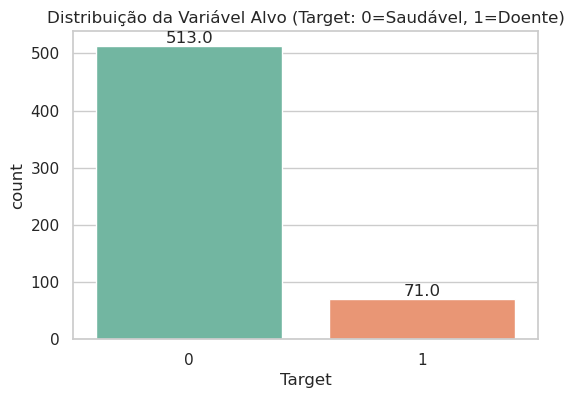

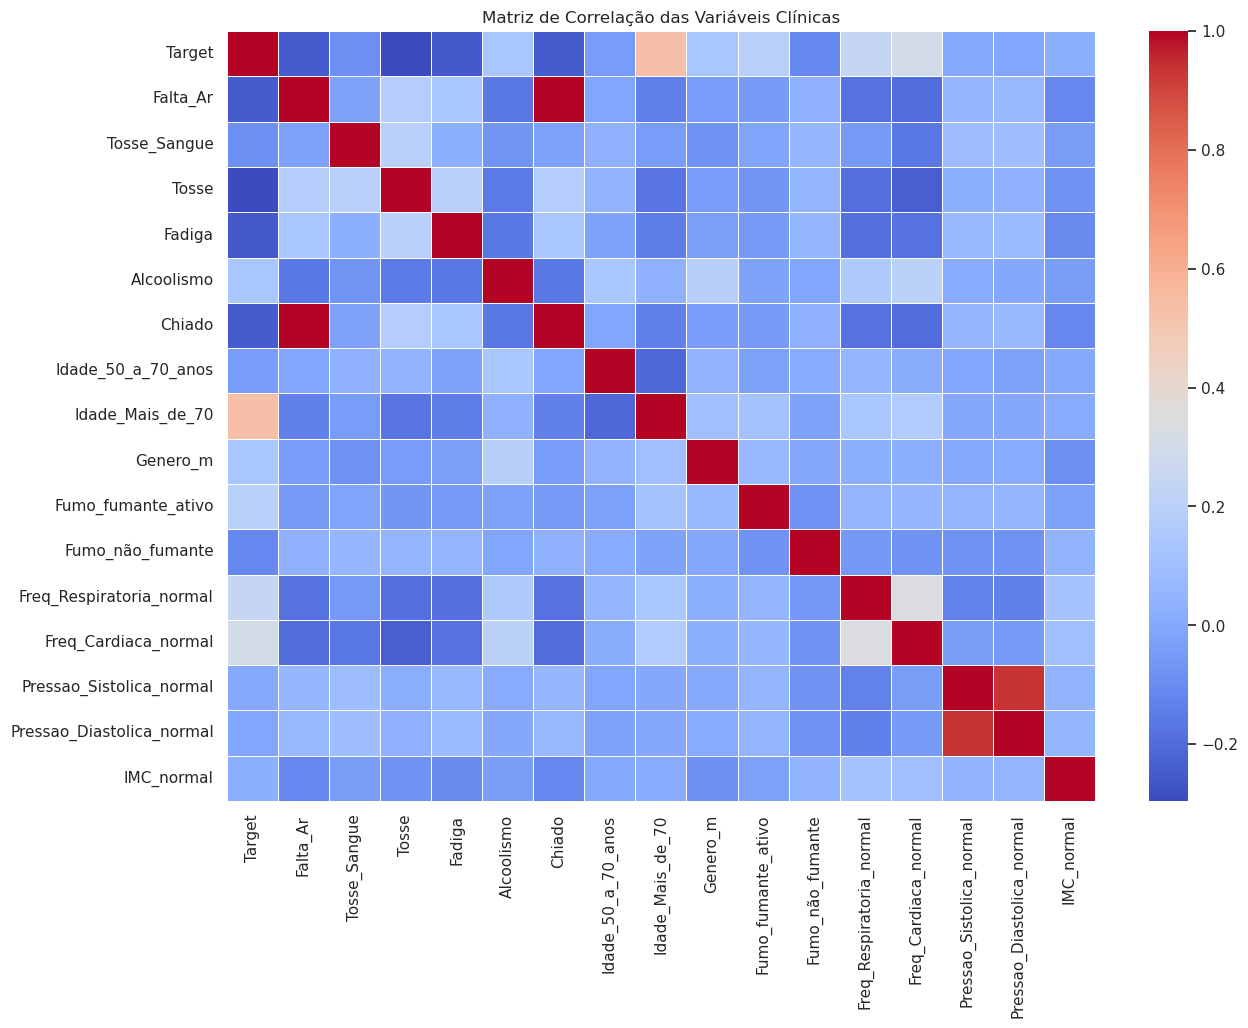


Preparando o ambiente para treino dos modelos (Sem Data Leakage)
   -> Treino: (408, 16)
   -> Teste:  (176, 16)
_____________________________________________________________________________________
Iniciando Busca de Hiperparâmetros (GridSearchCV com Pipeline)...
Critério Primário: Recall | Critérios Secundários: Especificidade, ROC-AUC e F1-score
_____________________________________________________________________________________
MODELO                 | RECALL (± DESVIO)  | ESPECIF. (± DESVIO) 
_____________________________________________________________________________________
Baseline (Dummy)       |   8.00% ± 7.48%    |    87.16% ± 0.98%   
Regressão Logística    |   96.00% ± 4.90%   |    70.95% ± 4.48%   
Árvore de Decisão      |   94.00% ± 4.90%   |    76.56% ± 4.43%   
Random Forest          |  58.00% ± 11.66%   |    89.95% ± 3.23%   
SVM (Support Vector)   |   94.00% ± 4.90%   |    78.77% ± 2.21%   
Gradient Boosting      |  44.00% ± 20.59%   |    97.76% ± 2.89%   

[Arqui

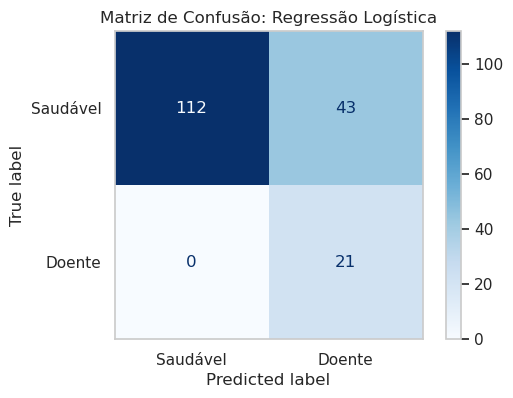

AUC-ROC: 0.947 | AUC-PR: 0.724 | Prevalência: 0.119


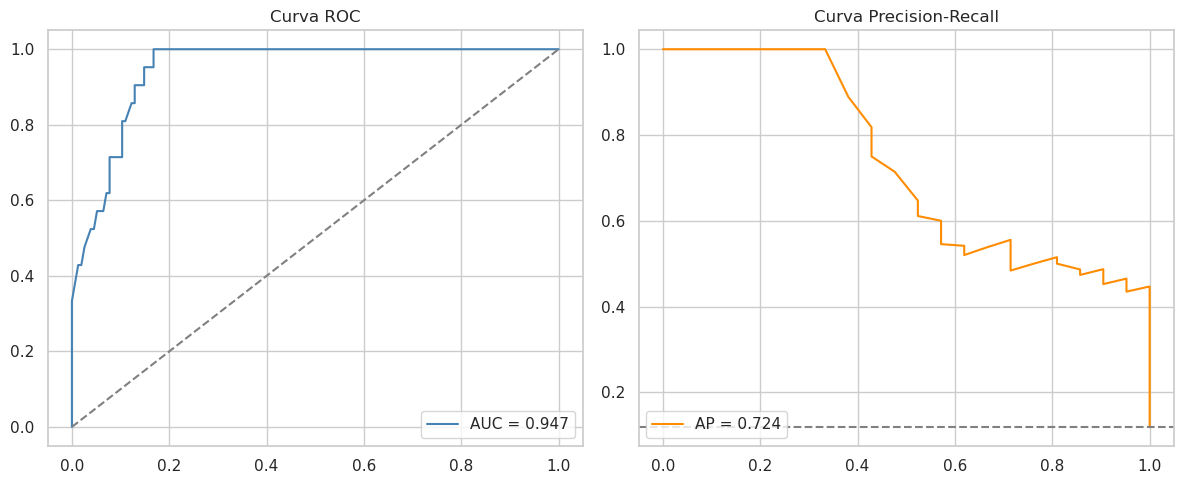


🔍 Analisando Falsos Negativos (Casos Críticos)...
Total de Falsos Negativos identificados no teste: 0

--- EXPORTANDO MODELO PARA PRODUÇÃO ---
Modelo salvo com sucesso no arquivo: modelo_helena_final.pkl
_____________________________________________________________________________________

🔍 Investigando Robustez (Permutation Importance no Teste)...


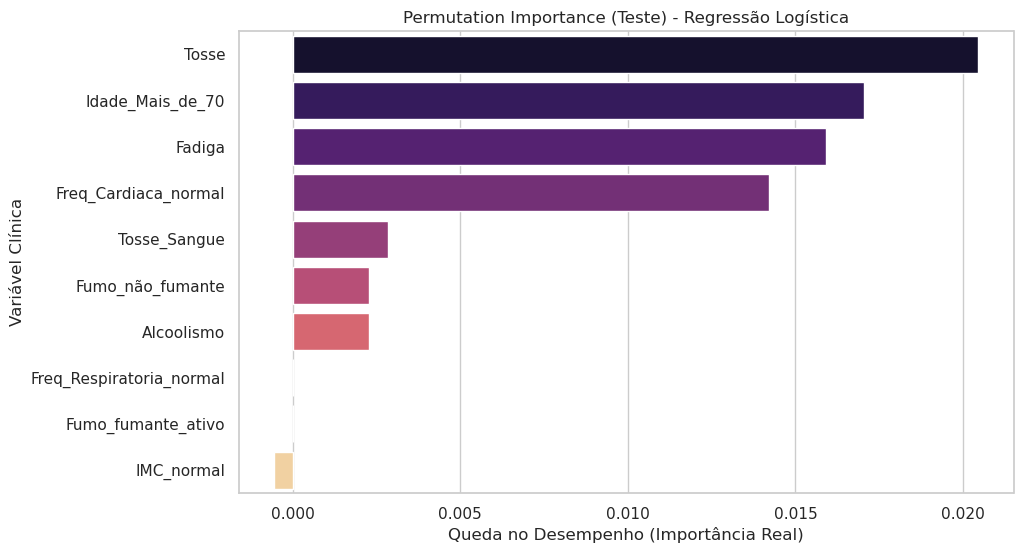

Background dataset has 408 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=408 when initializing the masker.



=== EXPLICABILIDADE COM SHAP ===

1. SHAP Summary Plot (Impacto Global das Variáveis):


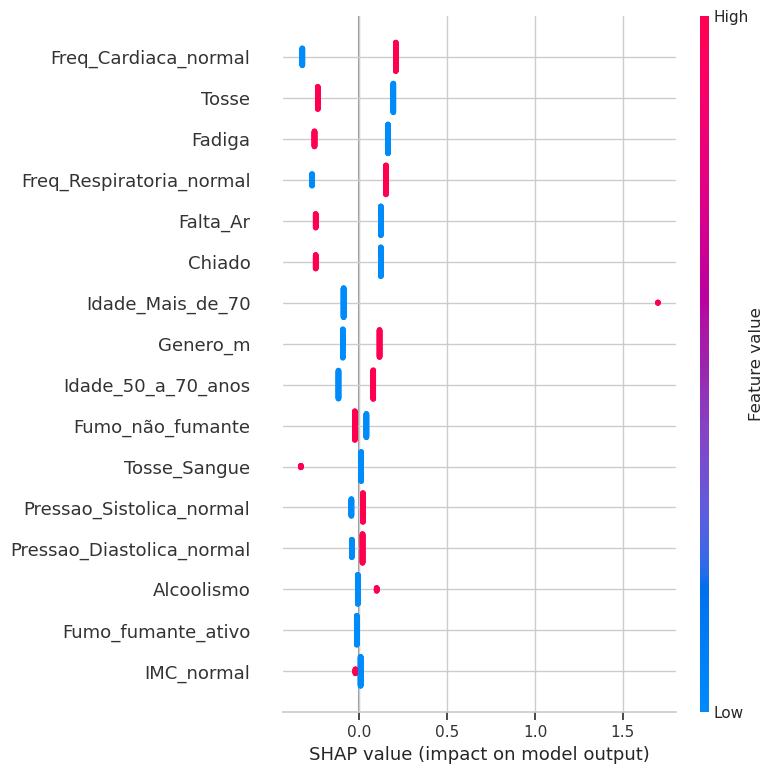


2. SHAP Waterfall Plot (Explicabilidade Local do primeiro paciente no teste):


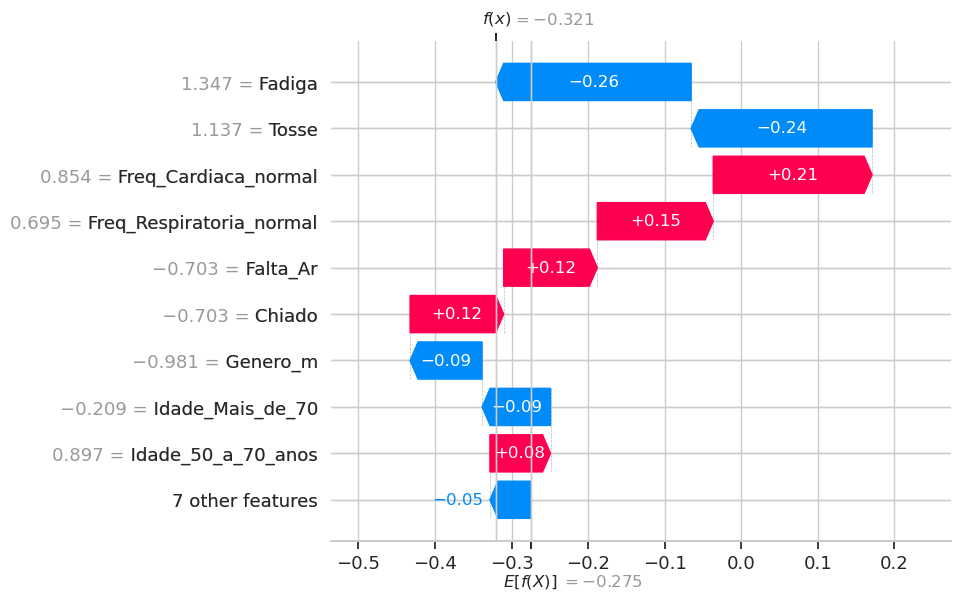

In [17]:
def gerar_grafico_importancia(modelo, nome_modelo, x_teste, y_teste):
    print("\n🔍 Investigando Robustez (Permutation Importance no Teste)...")
    resultado_pi = permutation_importance(modelo, x_teste, y_teste, n_repeats=10, random_state=42, n_jobs=-1)
    
    df_pi = pd.DataFrame({
        'Feature': x_teste.columns,
        'Importancia_Permutacao': resultado_pi.importances_mean,
        'Desvio': resultado_pi.importances_std
    }).sort_values(by='Importancia_Permutacao', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importancia_Permutacao', y='Feature', data=df_pi.head(10), palette='magma')
    plt.title(f"Permutation Importance (Teste) - {nome_modelo}")
    plt.xlabel("Queda no Desempenho (Importância Real)")
    plt.ylabel("Variável Clínica")
    plt.show()

def aplicar_shap(modelo, x_treino, x_teste):
    print("\n=== EXPLICABILIDADE COM SHAP ===")
    
    # 1. Se o modelo for um Pipeline, separamos o pré-processamento do classificador
    if hasattr(modelo, "named_steps"):
        scaler = modelo.named_steps['scaler']
        classificador = modelo.named_steps['clf']
        
        # O SHAP precisa visualizar os dados na mesma escala em que o modelo foi treinado
        x_treino_shap = pd.DataFrame(scaler.transform(x_treino), columns=x_treino.columns)
        x_teste_shap = pd.DataFrame(scaler.transform(x_teste), columns=x_teste.columns)
    else:
        classificador = modelo
        x_treino_shap = x_treino
        x_teste_shap = x_teste

    try:
        # Tenta aplicar o LinearExplainer (ideal para Regressão Logística)
        explainer = shap.LinearExplainer(classificador, x_treino_shap)
        shap_values = explainer(x_teste_shap)
        
        print("\n1. SHAP Summary Plot (Impacto Global das Variáveis):")
        shap.summary_plot(shap_values, x_teste_shap)
        
        print("\n2. SHAP Waterfall Plot (Explicabilidade Local do primeiro paciente no teste):")
        shap.plots.waterfall(shap_values[0])
        
    except Exception:
        print("Modelo não-linear detectado. Aplicando o Explainer de Árvore/Genérico...")
        # O shap.Explainer é inteligente o suficiente para aplicar TreeExplainer em Random Forest/Árvores
        explainer = shap.Explainer(classificador, x_treino_shap)
        shap_values = explainer(x_teste_shap)
        
        print("\n1. SHAP Summary Plot (Impacto Global das Variáveis):")
        shap.summary_plot(shap_values, x_teste_shap)
        
        # Em modelos baseados em árvore, o formato do array gerado pode mudar ligeiramente
        if len(shap_values.shape) > 2:
            shap_values = shap_values[:, :, 1]
            
        print("\n2. SHAP Waterfall Plot (Explicabilidade Local do primeiro paciente no teste):")
        shap.plots.waterfall(shap_values[0])
if __name__ == "__main__":
    # Carrega os dados brutos (com todas as colunas e IDs)
    df_sujo = carregar_dataset("dataset_completo_v2.csv")
    
    if df_sujo is not None:
        # 1. Investiga as duplicatas, filtra as colunas e remove o ID
        df = investigar_duplicatas(df_sujo)
        
        # 2. Transforma dados em 0 e 1, arruma dummies, etc.
        df = tratar_dados(df)
        
        # 3. Roda a Análise Exploratória (EDA)
        gerar_eda(df, 'Target')
        
        # 4. Prepara treino e teste com Pipeline (sem Data Leakage)
        x_treino, x_teste, y_treino, y_teste, pipelines = preparar_dados_treino(df, "Target")
        
        # 5. Otimiza, avalia pelo Recall e salva o arquivo de Folds
        modelo, nome_modelo = otimizar_e_comparar_algoritmos(x_treino, y_treino, pipelines)
        
        # 6. Avaliação final no conjunto de Teste isolado
        predicao = modelo.predict(x_teste)
        gerar_relatorio_metricas(y_teste, predicao)
        gerar_matriz_confusao(y_teste, predicao, nome_modelo)
        avaliar_curvas(modelo, nome_modelo, x_teste, y_teste)
        analisar_erros(x_teste, y_teste, predicao)
        
        # 7. Salva o modelo para uso futuro
        exportar_modelo(modelo)
        
        # 8. Explicabilidade (Permutation e SHAP)
        gerar_grafico_importancia(modelo, nome_modelo, x_teste, y_teste)
        aplicar_shap(modelo, x_treino, x_teste)